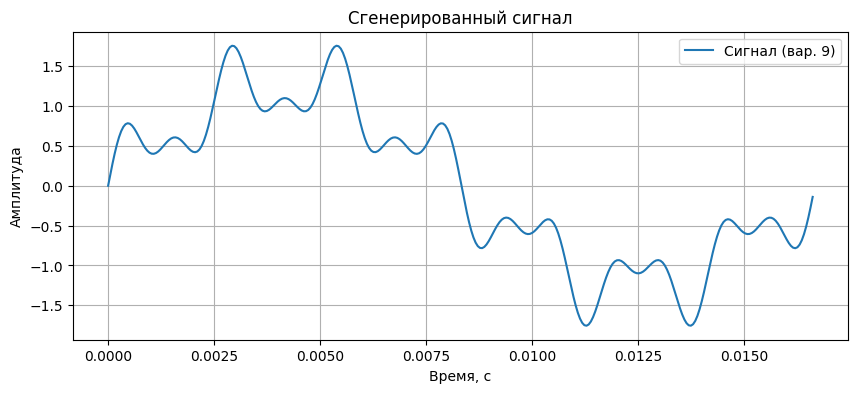

--- СРАВНЕНИЕ ВРЕМЕНИ ВЫПОЛНЕНИЯ ---
Численный ряд Фурье (CFT): 0.004011 сек
Дискретное преобразование (DFT): 0.041096 сек
Быстрое преобразование (FFT): 0.001899 сек
Ускорение FFT относительно DFT: 21.6 раз

--- НАЙДЕННЫЕ АМПЛИТУДЫ ГАРМОНИК (DFT) ---
Гармоника №1 (60 Гц): Амплитуда = 1.250
Гармоника №7 (420 Гц): Амплитуда = 0.400
Гармоника №13 (780 Гц): Амплитуда = 0.250


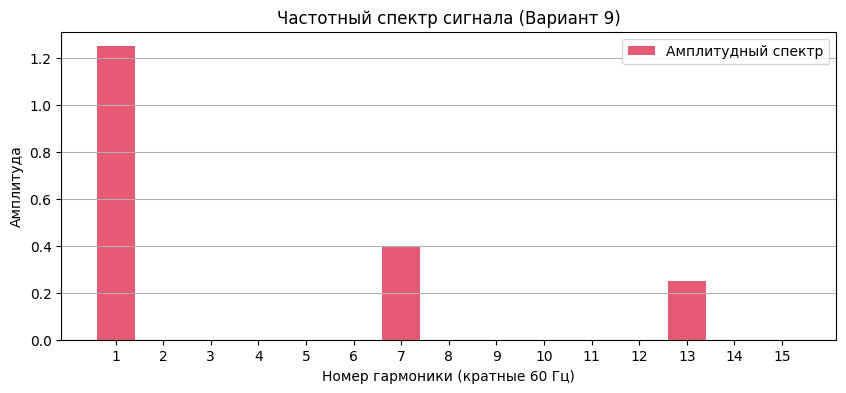

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import time

# 1. ИСХОДНЫЕ ДАННЫЕ ДЛЯ ВАРИАНТА 9
A1, f1 = 1.25, 60
A2, f2 = 0.4, 420
A3, f3 = 0.25, 780

# Расчет шага дискретизации по условию: >= 20 точек на период высшей гармоники (f3)
T_min = 1 / f3  # Период высшей гармоники
points_per_period = 25  # Выберем 25 точек (> 20)
h = T_min / points_per_period  # Шаг дискретизации

# Генерируем сигнал длительностью ровно в один период основной гармоники (f1)
# Это исключит смещение номеров гармоник при ДПФ/БПФ
ts = 1 / f1  
N = int(np.ceil(ts / h))
t = np.linspace(0, ts, N, endpoint=False)

# Сгенерированный полигармонический сигнал
u = A1 * np.sin(2 * np.pi * f1 * t) + A2 * np.sin(2 * np.pi * f2 * t) + A3 * np.sin(2 * np.pi * f3 * t)

# Вывод графика исходного сигнала
plt.figure(figsize=(10, 4))
plt.plot(t, u, label='Сигнал (вар. 9)')
plt.title('Сгенерированный сигнал')
plt.xlabel('Время, с')
plt.ylabel('Амплитуда')
plt.grid(True)
plt.legend()
plt.show()

# Ограничимся поиском первых 15 гармоник для наглядности
max_harmonics = 15
harmonics_range = np.arange(1, max_harmonics + 1)

# =====================================================================
# ПУНКТ 1.1: РАЗЛОЖЕНИЕ В РЯД ФУРЬЕ (ЧИСЛЕННОЕ ИНТЕГРИРОВАНИЕ)
# =====================================================================
t0 = time.time()
w = 2 * np.pi * f1
a = np.zeros(max_harmonics)
b = np.zeros(max_harmonics)

for k in range(max_harmonics):
    h_harmonic = ts / (N - 1)
    a[k] = (h_harmonic / ts) * (1 + u[-1] * np.cos((k + 1) * w * ts) + 
                                2 * np.sum(u[:-1] * np.cos((k + 1) * w * t[:-1])))
    b[k] = (h_harmonic / ts) * (u[-1] * np.sin((k + 1) * w * ts) + 
                                2 * np.sum(u[:-1] * np.sin((k + 1) * w * t[:-1])))

F_cft = np.sqrt(a**2 + b**2)
t_cft = time.time() - t0

# =====================================================================
# ПУНКТ 1.2: ДИСКРЕТНОЕ ПРЕОБРАЗОВАНИЕ ФУРЬЕ (ДПФ / DFT вручную)
# =====================================================================
t0 = time.time()
X_dft = np.zeros(N, dtype=complex)
for k in range(N):
    X_dft[k] = np.sum(u * np.exp(-2 * np.pi * 1j * k * np.arange(N) / N))

# Пересчет в реальные амплитуды (берем первые max_harmonics)
F_dft = (2 / N) * np.abs(X_dft[1:max_harmonics + 1])
t_dft = time.time() - t0

# =====================================================================
# ПУНКТ 1.3: БЫСТРОЕ ПРЕОБРАЗОВАНИЕ ФУРЬЕ (БПФ / FFT встроенная)
# =====================================================================
t0 = time.time()
X_fft = np.fft.fft(u)
F_fft = (2 / N) * np.abs(X_fft[1:max_harmonics + 1])
t_fft = time.time() - t0

# =====================================================================
# ВЫВОД РЕЗУЛЬТАТОВ И СРАВНЕНИЕ ВРЕМЕНИ
# =====================================================================
print("--- СРАВНЕНИЕ ВРЕМЕНИ ВЫПОЛНЕНИЯ ---")
print(f"Численный ряд Фурье (CFT): {t_cft:.6f} сек")
print(f"Дискретное преобразование (DFT): {t_dft:.6f} сек")
print(f"Быстрое преобразование (FFT): {t_fft:.6f} сек")
print(f"Ускорение FFT относительно DFT: {t_dft / t_fft:.1f} раз\n")

print("--- НАЙДЕННЫЕ АМПЛИТУДЫ ГАРМОНИК (DFT) ---")
for k in range(max_harmonics):
    freq = (k + 1) * f1
    if F_dft[k] > 0.05:  # выводим только значимые
        print(f"Гармоника №{k+1} ({freq} Гц): Амплитуда = {F_dft[k]:.3f}")

# Построение гистограммы спектра
plt.figure(figsize=(10, 4))
plt.bar(harmonics_range, F_dft, color='crimson', alpha=0.7, label='Амплитудный спектр')
plt.title('Частотный спектр сигнала (Вариант 9)')
plt.xlabel('Номер гармоники (кратные 60 Гц)')
plt.ylabel('Амплитуда')
plt.xticks(harmonics_range)
plt.grid(True, axis='y')
plt.legend()
plt.show()
